# Structural Dynamics, Stability, and Solvation Profiling of the TCF4–DNA Complex

## Purpose & Objectives
This comprehensive analysis evaluates the conformational stability, flexibility, and hydration architecture of the **TCF4–DNA transcription factor complex**. By combining trajectory-wide structural dynamics metrics with high-performance solvent tracking, this workflow resolves both global complex stability and the specific water-mediated hydrogen-bonding networks that stabilize the protein–DNA interface.

In [1]:
# Install once (if a package is missing), then restart the kernel.
# --user is needed on a cluster where you can't write to the system Python.
# %pip install --user mdanalysis py3Dmol scipy pandas matplotlib

import MDAnalysis as mda
from MDAnalysis.analysis import align, rms
import matplotlib.pyplot as plt
print("MDAnalysis", mda.__version__)

MDAnalysis 2.10.0


0. **Setup**
   * Loads all `step5_N.dcd` segments in order, keeps both protein chains and both DNA strands together across the periodic box, and makes a small in-memory protein + DNA trajectory. Run this cell before any of the others.

In [2]:
# ==============================================================================
# 0. SETUP -- run this cell first. Every analysis cell below uses what it makes.
#    The step5_N.dcd segments are read directly (in numerical order), so catdcd
#    and a combined step5.dcd are no longer needed.
# ==============================================================================
import os, re, io, math, tempfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import MDAnalysis as mda
from MDAnalysis.analysis import align, rms
from MDAnalysis.analysis.base import AnalysisFromFunction
from MDAnalysis.coordinates.memory import MemoryReader
from MDAnalysis.lib.distances import capped_distance, minimize_vectors
from MDAnalysis.transformations import unwrap

warnings.filterwarnings("ignore")

# ---- settings ----------------------------------------------------------------
PSF        = "step3_input.psf"
REF_PDB    = "step3_input.pdb"
SEG_PREFIX = "step5"        # reads step5_1.dcd, step5_2.dcd, ...
TIMESTEP_FS = 2.0           # NAMD timestep
DCDFREQ     = 5000          # NAMD dcdfreq (steps between saved frames)
STRIDE      = 1             # use every Nth frame (e.g. 10 for a quick test run)
ATOM_MODE   = "all"         # RMSD / RMSF atoms: "all" (all atoms), "heavy" (no H),
                            #                    or "backbone" (protein Cα, DNA P)

PROTEIN = "segid PROA PROB"
DNA     = "segid DNAA DNAB"
COMPLEX = "segid PROA PROB DNAA DNAB"
WATER_O = "resname TIP3 HOH and name OH2 O"     # bulk + crystal water oxygens

MODE_LABEL = {"all": "all-atom", "heavy": "heavy-atom", "backbone": "Cα / P"}[ATOM_MODE]

def atoms_sel(base, backbone):
    """Selection for `base` in the chosen ATOM_MODE (`backbone` = names used in backbone mode)."""
    if ATOM_MODE == "backbone":
        return f"({base}) and ({backbone})"
    if ATOM_MODE == "heavy":
        return f"({base}) and not name H*"
    return base

FRAME_DT_NS = TIMESTEP_FS * DCDFREQ / 1e6       # 0.01 ns between saved frames
DT_NS = FRAME_DT_NS * STRIDE                    # time between frames we analyse

# ---- find and load the trajectory segments -------------------------------------
pat = re.compile(rf"^{re.escape(SEG_PREFIX)}_(\d+)\.dcd$")
segments = sorted((int(m.group(1)), f) for f in os.listdir(".") if (m := pat.match(f)))
segments = [f for _, f in segments]
if not segments:
    raise FileNotFoundError(f"No {SEG_PREFIX}_N.dcd files in {os.getcwd()}")
print(f"Segments: {segments[0]} ... {segments[-1]} ({len(segments)} files)")

u = mda.Universe(PSF, segments)
ref = mda.Universe(PSF, REF_PDB)
print(f"DCD header says {u.trajectory.dt:g} ps per frame; settings say {FRAME_DT_NS*1000:g} ps")

# ---- keep both protein chains and both DNA strands together across the box ----
complex_atoms = u.select_atoms(COMPLEX)
chain_ids = list(dict.fromkeys(complex_atoms.segids))      # PROA, PROB, DNAA, DNAB
print("Chains:", ", ".join(f"{s} ({complex_atoms.select_atoms(f'segid {s}').residues.n_residues} res)"
                          for s in chain_ids))

def keep_together(groups):
    """Each frame: move each chain to the periodic image next to the chains already placed."""
    idx = [g.indices for g in groups]
    def transform(ts):
        if ts.dimensions is None:
            return ts
        pos = ts.positions
        placed = list(idx[0])
        for ix in idx[1:]:
            d = pos[ix].mean(axis=0) - pos[placed].mean(axis=0)
            d_min = minimize_vectors(d[None, :].astype(np.float64), ts.dimensions)[0]
            pos[ix] += (d_min - d).astype(pos.dtype)
            placed.extend(ix)
        ts.positions = pos
        return ts
    return transform

u.trajectory.add_transformations(
    unwrap(complex_atoms),
    keep_together([complex_atoms.select_atoms(f"segid {s}") for s in chain_ids]),
)

n_frames = len(range(0, u.trajectory.n_frames, STRIDE))
time_ns = np.arange(n_frames) * DT_NS
print(f"Frames: {u.trajectory.n_frames} total, using {n_frames} "
      f"({DT_NS:g} ns apart) = {time_ns[-1] + DT_NS:.1f} ns")

# ---- small in-memory copy of just protein + DNA (fast RMSD / RMSF) --------------
print("Loading protein + DNA coordinates into memory ...")
coords = AnalysisFromFunction(lambda ag: ag.positions.copy(), complex_atoms).run(
    step=STRIDE).results.timeseries
cx = mda.Merge(complex_atoms).load_new(coords, format=MemoryReader, dt=DT_NS * 1000)
ref_cx = mda.Merge(ref.select_atoms(COMPLEX))
print("Setup done.")

Segments: step5_1.dcd ... step5_100.dcd (100 files)
DCD header says 10 ps per frame; settings say 10 ps
Chains: PROA (62 res), PROB (61 res), DNAA (13 res), DNAB (12 res)
Frames: 10000 total, using 10000 (0.01 ns apart) = 100.0 ns
Loading protein + DNA coordinates into memory ...
Setup done.


1. **Initial 3D Structural Inspection**
   * Generated an interactive 3D baseline visualization of the unperturbed TCF4–DNA complex to verify initial topology, chain assignments, and domain alignment.

In [3]:
import py3Dmol

# 1. Read CHARMM-GUI PDB file
with open("step3_input.pdb", "r") as f:
    lines = f.readlines()

# 2. Remap CHARMM segids (cols 73-76) to standard 1-character PDB Chain IDs (col 22)
modified_lines = []
for line in lines:
    if line.startswith(("ATOM", "HETATM")):
        segid = line[72:76].strip()
        
        # Protein and DNA mappings
        if segid == "PROA":
            chain_id = "A"
        elif segid == "PROB":
            chain_id = "B"
        elif segid == "DNAA":
            chain_id = "W"
        elif segid == "DNAB":
            chain_id = "X"
        # Crystal waters mapped to Chain C
        elif segid in ["WATA", "WATB", "WATC", "WATD"]:
            chain_id = "C"
        else:
            chain_id = line[21]  # Keep original for bulk solvent / ions
            
        # Reconstruct line with updated Chain ID at index 21 (Column 22)
        line = line[:21] + chain_id + line[22:]
        
    modified_lines.append(line)

pdb_str = "".join(modified_lines)

# 3. Initialize py3Dmol viewer
view = py3Dmol.view(width=800, height=500)
view.addModel(pdb_str, "pdb")

# 4. Clear default representation
view.setStyle({}, {})

# 5. Protein Chain A (PROA): Cyan cartoon
view.addStyle({'chain': 'A'}, {'cartoon': {'color': 'cyan'}})

# 6. Protein Chain B (PROB): Magenta cartoon
view.addStyle({'chain': 'B'}, {'cartoon': {'color': 'magenta'}})

# 7. DNA Chain W (DNAA): Dark Orange cartoon + nucleic bases
view.addStyle(
    {'chain': 'W'}, 
    {'cartoon': {'color': '#e66101'}, 'stick': {'colorscheme': 'nucleic'}}
)

# 8. DNA Chain X (DNAB): Light Orange cartoon + nucleic bases
view.addStyle(
    {'chain': 'X'}, 
    {'cartoon': {'color': '#fdb863'}, 'stick': {'colorscheme': 'nucleic'}}
)

# 9. Crystal Waters (WATA, WATB, WATC, WATD -> Chain C): Red/Coral spheres
view.addStyle(
    {'chain': 'C'}, 
    {'sphere': {'scale': 0.35, 'color': '#ff4b4b', 'opacity': 0.9}}
)

# 10. Bulk Solvation Waters (TIP3/SOLV): Light blue transparent spheres
view.addStyle(
    {'resn': ['TIP3', 'SOLV'], 'chain': ' '}, 
    {'sphere': {'scale': 0.20, 'color': 'lightblue', 'opacity': 0.3}}
)

# 11. Zoom directly onto protein-DNA complex + crystal waters (ignoring bulk box)
view.zoomTo({'chain': ['A', 'B', 'W', 'X', 'C']})
view.rotate(0, 'x')
view.rotate(0, 'y')
view.rotate(90, 'z')
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Figure 1: Initial structure of TCF4 bHLH, a homodimer bound to 13-bp E-box DNA. The proteins are represented as cartoons (chain A, cyan; Chain B, magenta), DNA as chain (chain W, dark orange; chain X, light orange), Crystal waters red/coral spheres. 

2. **Global Trajectory Stability (RMSD Analysis)**
   * Calculated all-atom Root Mean Square Deviation (RMSD) across time for each TCF4 chain, each DNA strand, and the full complex (set `ATOM_MODE` in the setup cell for heavy-atom or Cα / P).
   * Confirmed overall structural convergence and structural equilibrium across the MD trajectory.

Protein Chain A : 1060 atoms
Protein Chain B : 1036 atoms
DNA Strand 1    : 411 atoms
DNA Strand 2    : 381 atoms
Full Complex    : 2888 atoms


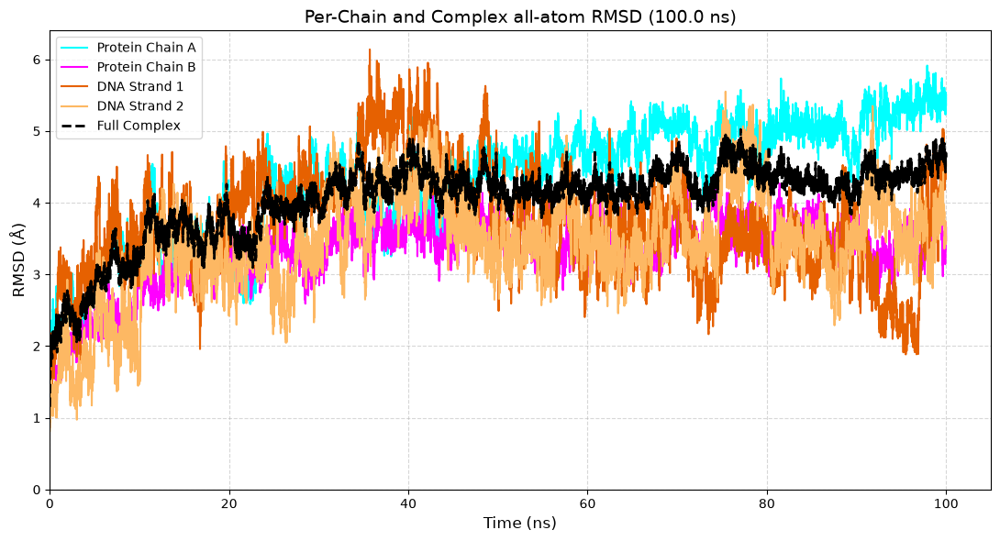

In [4]:
# RMSD of each chain vs. the starting structure (each selection is fitted on itself)
# Atoms used are set by ATOM_MODE in the setup cell (default: all atoms)
DNA_BACKBONE = "name P C5' C3' O5' O3'"
selections = {
    "Protein Chain A": atoms_sel("segid PROA", "name CA"),
    "Protein Chain B": atoms_sel("segid PROB", "name CA"),
    "DNA Strand 1": atoms_sel("segid DNAA", DNA_BACKBONE),
    "DNA Strand 2": atoms_sel("segid DNAB", DNA_BACKBONE),
    "Full Complex": atoms_sel(COMPLEX, "name CA P"),
}
for label, sel_str in selections.items():
    print(f"{label:16s}: {cx.select_atoms(sel_str).n_atoms} atoms")
colors = {
    "Protein Chain A": "cyan",
    "Protein Chain B": "magenta",
    "DNA Strand 1": "#e66101",
    "DNA Strand 2": "#fdb863",
    "Full Complex": "black",
}

rmsd_results = {}
for label, sel_str in selections.items():
    rmsd_results[label] = rms.RMSD(cx, ref_cx, select=sel_str).run().results.rmsd[:, 2]

pd.DataFrame({"time_ns": time_ns, **rmsd_results}).to_csv("rmsd.csv", index=False)

total_time_ns = time_ns[-1] + DT_NS
plt.figure(figsize=(11, 6))
for label, values in rmsd_results.items():
    ls = "--" if label == "Full Complex" else "-"
    lw = 2.0 if label == "Full Complex" else 1.5
    plt.plot(time_ns, values, label=label, color=colors[label], linestyle=ls, linewidth=lw)
plt.xlabel("Time (ns)", fontsize=12)
plt.ylabel("RMSD (Å)", fontsize=12)
plt.title(f"Per-Chain and Complex {MODE_LABEL} RMSD ({total_time_ns:.1f} ns)", fontsize=14)
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.legend(loc="upper left", frameon=True)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

3. **Local Residue Flexibility (RMSF Profiling)**
   * Computed all-atom Root Mean Square Fluctuation (RMSF) for every atom, averaged per residue / nucleotide, to identify rigid secondary structure elements versus flexible loop regions and terminal tails.

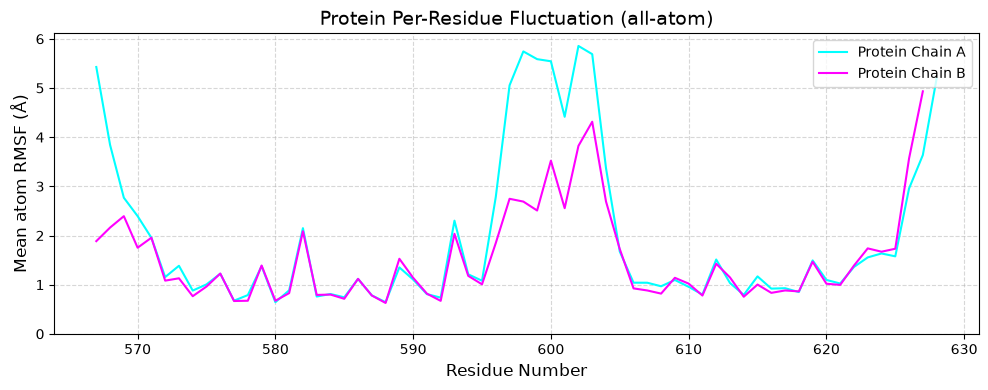

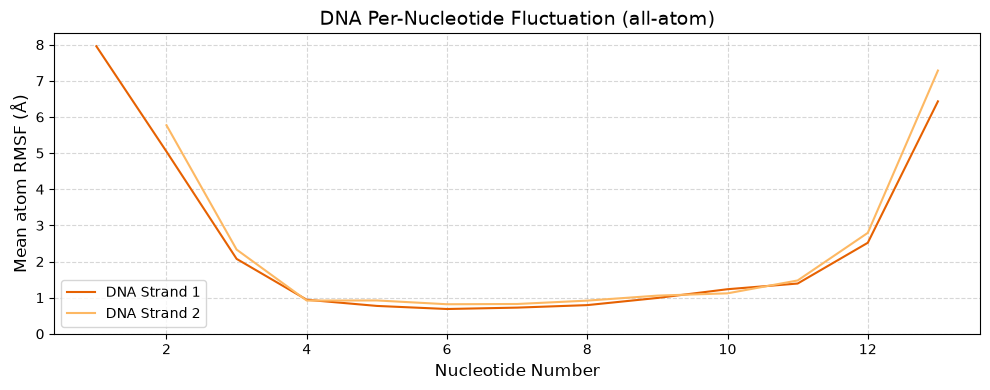

In [5]:
# Align the in-memory protein + DNA trajectory on the protein (both chains)
align.AlignTraj(cx, ref_cx, select=atoms_sel(PROTEIN, "name CA"), in_memory=True).run()

def plot_rmsf(atoms, chains, xlabel, title):
    # RMSF of every atom, then averaged over the atoms of each residue / nucleotide
    per_atom = pd.DataFrame({"segid": atoms.segids, "resid": atoms.resids,
                             "resname": atoms.resnames, "atom": atoms.names,
                             "rmsf_A": rms.RMSF(atoms).run().results.rmsf})
    per_res = (per_atom.groupby(["segid", "resid", "resname"], sort=False)["rmsf_A"]
               .agg(rmsf_A="mean", max_atom_rmsf_A="max", n_atoms="size").reset_index())
    plt.figure(figsize=(10, 4))
    for segid, label, color in chains:
        g = per_res[per_res["segid"] == segid]
        plt.plot(g["resid"], g["rmsf_A"], label=label, color=color, linewidth=1.5)
    plt.xlabel(xlabel, fontsize=12)
    plt.ylabel("RMSF (Å)" if ATOM_MODE == "backbone" else "Mean atom RMSF (Å)", fontsize=12)
    plt.ylim(bottom=0)
    plt.title(title, fontsize=14)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()
    return per_res, per_atom

# A. Protein RMSF (PROA and PROB)
rmsf_protein, rmsf_protein_atoms = plot_rmsf(
    cx.select_atoms(atoms_sel(PROTEIN, "name CA")),
    [("PROA", "Protein Chain A", "cyan"), ("PROB", "Protein Chain B", "magenta")],
    "Residue Number", f"Protein Per-Residue Fluctuation ({MODE_LABEL})")

# B. DNA RMSF (DNAA and DNAB)
rmsf_dna, rmsf_dna_atoms = plot_rmsf(
    cx.select_atoms(atoms_sel(DNA, "name P")),
    [("DNAA", "DNA Strand 1", "#e66101"), ("DNAB", "DNA Strand 2", "#fdb863")],
    "Nucleotide Number", f"DNA Per-Nucleotide Fluctuation ({MODE_LABEL})")

pd.concat([rmsf_protein, rmsf_dna]).to_csv("rmsf.csv", index=False)               # per residue
pd.concat([rmsf_protein_atoms, rmsf_dna_atoms]).to_csv("rmsf_atoms.csv", index=False)  # per atom

Figure 3: All atom RMSF of TCF4 R576T bHLH (replicate 2) over 100 ns. RMSF for Proteins chain A and B showed the greatest flunctuation between residues 595-605. This corresponds to the loop connecting the 2 helices. The mutation site (residue 576) remains comparitively rigid at ~1.2 angstroms. DNA remains much more rigid through the central E-box, ~1 angrstroms, and rise sharply at terminal base pairs. This is consistent with ends fraying in DNA strands. 

4. **Interfacial Water Residence Kinetics**
   * Implemented high-performance spatial indexing and vectorized tracking to evaluate solvent kinetics at the protein–DNA interface.
   * Isolated long-lived structural water molecules demonstrating continuous, uninterrupted residence times of ≥ 1.0 ns (≥ 100 frames) within 3.5 Å of both TCF4 and DNA heavy atoms.

Tracking 17491 water oxygens over 10000 frames ...
  500/10000 frames
  1000/10000 frames
  1500/10000 frames
  2000/10000 frames
  2500/10000 frames
  3000/10000 frames
  3500/10000 frames
  4000/10000 frames
  4500/10000 frames
  5000/10000 frames
  5500/10000 frames
  6000/10000 frames
  6500/10000 frames
  7000/10000 frames
  7500/10000 frames
  8000/10000 frames
  8500/10000 frames
  9000/10000 frames
  9500/10000 frames
17159 waters visited the interface; longest stay 66.29 ns
Fast Component (Bulk Exchange):    tau1 = 0.037 ns (Weight: 0.67)
Slow Component (Bound Waters):     tau2 = 1.349 ns (Weight: 0.22)
Weighted Mean Residence Time:      <tau> = 0.363 ns


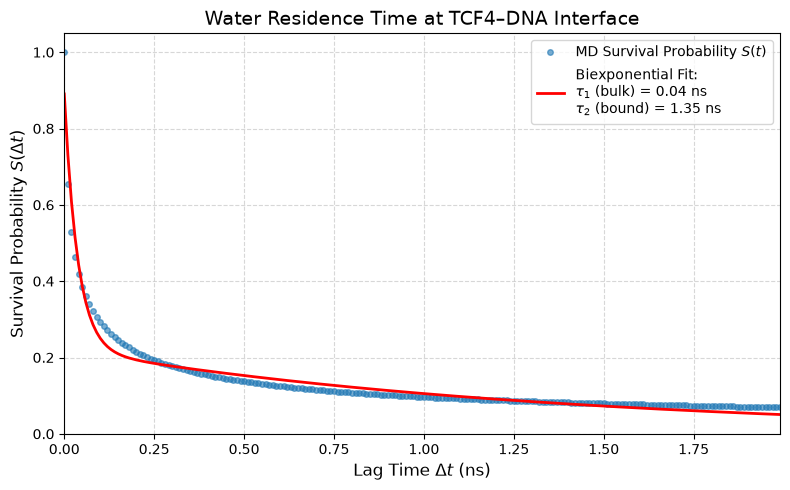

In [2]:
from scipy.optimize import curve_fit

# Settings
CUTOFF = 3.5        # Å, water O to protein / DNA heavy atom
TAU_MAX_NS = 2.0    # longest lag time for S(t)

protein_heavy = u.select_atoms(f"({PROTEIN}) and not name H*")
dna_heavy = u.select_atoms(f"({DNA}) and not name H*")
water_oxygens = u.select_atoms(WATER_O)
n_waters = water_oxygens.n_atoms
print(f"Tracking {n_waters} water oxygens over {n_frames} frames ...")

# 1. Which waters are within CUTOFF of BOTH protein and DNA in each frame?
#    (distances use the periodic box, so waters across the box edge are counted)
is_at_interface = np.zeros((n_frames, n_waters), dtype=bool)
for i, ts in enumerate(u.trajectory[::STRIDE]):
    near_p = capped_distance(water_oxygens.positions, protein_heavy.positions, CUTOFF,
                             box=ts.dimensions, return_distances=False)
    near_d = capped_distance(water_oxygens.positions, dna_heavy.positions, CUTOFF,
                             box=ts.dimensions, return_distances=False)
    both = np.intersect1d(np.unique(near_p[:, 0]), np.unique(near_d[:, 0]))
    is_at_interface[i, both] = True
    if i and i % 500 == 0:
        print(f"  {i}/{n_frames} frames")

# 2. Continuous residence: run_len[f, w] = frames water w stays from frame f onward
cols = np.where(is_at_interface.any(axis=0))[0]          # waters that ever visit
at = is_at_interface[:, cols]
run_len = np.zeros(at.shape, dtype=np.int32)
run_len[-1] = at[-1]
for f in range(n_frames - 2, -1, -1):
    run_len[f] = np.where(at[f], run_len[f + 1] + 1, 0)
max_streaks = np.zeros(n_waters, dtype=int)                # longest stay per water
if len(cols):
    max_streaks[cols] = run_len.max(axis=0)
print(f"{len(cols)} waters visited the interface; longest stay {max_streaks.max() * DT_NS:.2f} ns")

# 3. Continuous survival probability S(t)
tau_max = int(round(TAU_MAX_NS / DT_NS))
n_t0 = n_frames - tau_max
if n_t0 <= 0 or len(cols) == 0:
    raise RuntimeError("Trajectory too short for TAU_MAX_NS, or no interface waters found.")
R = run_len[:n_t0]
if (R > 0).sum() == 0:
    raise RuntimeError("No interface waters in the early frames -- try a smaller TAU_MAX_NS.")
survival_probs = np.array([(R > tau).sum() for tau in range(tau_max)]) / (R > 0).sum()
time_lag_ns = np.arange(tau_max) * DT_NS

# 4. Fit S(t) = A1*exp(-t/tau1) + A2*exp(-t/tau2)
def biexponential(t, a1, tau1, a2, tau2):
    return a1 * np.exp(-t / tau1) + a2 * np.exp(-t / tau2)

try:
    popt, _ = curve_fit(biexponential, time_lag_ns, survival_probs,
                        p0=[0.7, 0.1, 0.3, 1.0],
                        bounds=([0, 1e-4, 0, 1e-4], [1.0, 50.0, 1.0, 50.0]), maxfev=20000)
    a1, tau1, a2, tau2 = popt
    if tau1 > tau2:                       # keep tau1 = fast, tau2 = slow
        a1, tau1, a2, tau2 = a2, tau2, a1, tau1
        popt = [a1, tau1, a2, tau2]
    mean_residence_time = (a1 * tau1 + a2 * tau2) / (a1 + a2)
    print("=" * 55)
    print(f"Fast Component (Bulk Exchange):    tau1 = {tau1:.3f} ns (Weight: {a1:.2f})")
    print(f"Slow Component (Bound Waters):     tau2 = {tau2:.3f} ns (Weight: {a2:.2f})")
    print(f"Weighted Mean Residence Time:      <tau> = {mean_residence_time:.3f} ns")
    print("=" * 55)
except RuntimeError as e:
    popt = None
    print("Biexponential fit did not converge:", e)

pd.DataFrame({"lag_ns": time_lag_ns, "survival": survival_probs}).to_csv(
    "water_survival.csv", index=False)

# 5. Plot
plt.figure(figsize=(8, 5))
plt.plot(time_lag_ns, survival_probs, 'o', color='#1f77b4', markersize=4, alpha=0.6,
         label='MD Survival Probability $S(t)$')
if popt is not None:
    plt.plot(time_lag_ns, biexponential(time_lag_ns, *popt), 'r-', linewidth=2,
             label=f'Biexponential Fit:\n$\\tau_1$ (bulk) = {tau1:.2f} ns\n$\\tau_2$ (bound) = {tau2:.2f} ns')
plt.xlabel('Lag Time $\\Delta t$ (ns)', fontsize=12)
plt.ylabel('Survival Probability $S(\\Delta t)$', fontsize=12)
plt.title('Water Residence Time at TCF4–DNA Interface', fontsize=14)
plt.xlim(0, time_lag_ns[-1])
plt.ylim(0, 1.05)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

5. **Hydrogen Bond Profiling**
   * Quantified hydrogen-bond occupancies, donor–acceptor distances, and donor–hydrogen–acceptor angles between long-lived waters, TCF4 side chains, and DNA base/phosphate backbone atoms.


In [3]:
from MDAnalysis.analysis.hydrogenbonds import HydrogenBondAnalysis as HBA
from IPython.display import display

# Uses is_at_interface / max_streaks from the water residence cell above.
MIN_RESIDENCE_NS = 1.0

min_frames = math.ceil(MIN_RESIDENCE_NS / DT_NS)
long_lived = np.where(max_streaks >= min_frames)[0]
print(f"Found {len(long_lived)} water molecules bound continuously for >= {MIN_RESIDENCE_NS} ns.")
if len(long_lived) == 0:
    MIN_RESIDENCE_NS = 0.5
    print(f"Lowering threshold to {MIN_RESIDENCE_NS} ns ...")
    min_frames = math.ceil(MIN_RESIDENCE_NS / DT_NS)
    long_lived = np.where(max_streaks >= min_frames)[0]
    print(f"Found {len(long_lived)} water molecules.")
if len(long_lived) == 0:
    raise RuntimeError("No long-lived interface waters found -- nothing to analyse.")

# Whole water molecules (O + both H) for the long-lived waters
ll_water_atoms = water_oxygens[long_lived].residues.atoms
water_sel_str = "index " + " ".join(map(str, ll_water_atoms.indices))

print("Calculating hydrogen bonds between long-lived waters and protein / DNA ...")
hbonds = HBA(universe=u, between=[water_sel_str, COMPLEX],
             d_a_cutoff=3.5, d_h_a_angle_cutoff=150.0)
# only look at hydrogens / acceptors in these waters + the complex (much faster)
both_sel = f"({water_sel_str}) or ({COMPLEX})"
hbonds.hydrogens_sel = f"({hbonds.guess_hydrogens(both_sel)}) and ({both_sel})"
hbonds.acceptors_sel = f"({hbonds.guess_acceptors(both_sel)}) and ({both_sel})"
hbonds.run(step=STRIDE)

hbond_df = pd.DataFrame(hbonds.results.hbonds,
                        columns=["frame", "donor_index", "hydrogen_index",
                                 "acceptor_index", "distance", "angle"])
for c in ["frame", "donor_index", "hydrogen_index", "acceptor_index"]:
    hbond_df[c] = hbond_df[c].astype(int)
print(f"{len(hbond_df)} hydrogen bonds found.")

if len(hbond_df):
    water_is_donor = np.isin(hbond_df["donor_index"], ll_water_atoms.indices)
    solute = u.atoms[np.where(water_is_donor, hbond_df["acceptor_index"], hbond_df["donor_index"])]
    df_records = pd.DataFrame({
        "Solute_Segment": solute.segids,
        "Solute_Residue": [f"{rn}{ri}" for rn, ri in zip(solute.resnames, solute.resids)],
        "Solute_Atom": solute.names,
        "Frame": hbond_df["frame"].values,
    })
    # Occupancy = % of analysed frames in which this atom has >= 1 H-bond to a long-lived water
    occupancy_summary = (
        df_records.groupby(["Solute_Segment", "Solute_Residue", "Solute_Atom"])["Frame"]
        .nunique().reset_index(name="Hbond_Frames")
    )
    occupancy_summary["Occupancy_%"] = occupancy_summary["Hbond_Frames"] / n_frames * 100
    occupancy_summary = occupancy_summary.sort_values("Occupancy_%", ascending=False)
    occupancy_summary.to_csv("water_hbond_occupancy.csv", index=False)

    styled_summary = (
        occupancy_summary.head(20)
        .style
        .format({"Occupancy_%": "{:.1f}%"})
        .background_gradient(subset=["Occupancy_%"], cmap="Blues")
        .set_caption(f"<b>Top Protein & DNA Residues Anchored by Long-Lived Waters "
                     f"(&ge;{MIN_RESIDENCE_NS} ns)</b>")
        .set_table_styles([
            {"selector": "caption", "props": [("font-size", "16px"), ("text-align", "left"),
                                              ("margin-bottom", "10px")]},
            {"selector": "th", "props": [("background-color", "#f2f2f2"), ("font-weight", "bold")]},
        ])
    )
    display(styled_summary)

Found 49 water molecules bound continuously for >= 1.0 ns.
Calculating hydrogen bonds between long-lived waters and protein / DNA ...
268253 hydrogen bonds found.


,Solute_Segment,Solute_Residue,Solute_Atom,Hbond_Frames,Occupancy_%
26,DNAA,ADE6,O2P,9781,97.8%
330,PROB,GLU577,OE2,9759,97.6%
156,PROA,ARG578,NH2,9675,96.8%
282,PROB,ARG578,NH2,9646,96.5%
209,PROA,GLU577,OE2,9613,96.1%
239,PROA,LEU608,N,9502,95.0%
100,DNAB,ADE6,O2P,9485,94.8%
360,PROB,LEU608,N,9443,94.4%
35,DNAA,CYT5,O2P,9437,94.4%
105,DNAB,CYT5,O2P,9387,93.9%


Figure 6: The residues most likely to form long-lived bonds with water in TCF4 bHLH R576T (replicate 2). 

6. **Interfacial Water Visualization**
   * Quantified hydrogen-bond occupancies, donor–acceptor distances, and donor–hydrogen–acceptor angles between long-lived waters, TCF4 side chains, and DNA base/phosphate backbone atoms.
   * Developed a 3D rendering of the top structural waters in full atomic detail (O+H geometry), active Frame 0 H-bond vectors, and contacting residue side chains.


In [4]:
import py3Dmol

# 1. Top 6 waters by longest continuous stay at the interface
top6 = np.argsort(max_streaks)[::-1][:6]
top6 = top6[max_streaks[top6] > 0]
top6_water_atoms = water_oxygens[top6].residues.atoms          # O + H
top6_set = set(top6_water_atoms.indices)

# 2. Show the frame with the most H-bonds to these waters
#    (or, if they have none, the frame where most of them are at the interface)
top_rows = hbond_df[hbond_df["donor_index"].isin(top6_set) | hbond_df["acceptor_index"].isin(top6_set)]
if len(top_rows):
    frame_idx = int(top_rows["frame"].value_counts().idxmax())
else:
    frame_idx = int(np.argmax(is_at_interface[:, top6].sum(axis=1))) * STRIDE
u.trajectory[frame_idx]
print(f"Showing frame {frame_idx} ({frame_idx * FRAME_DT_NS:.2f} ns)")

# 3. Move each water to the periodic image next to the complex (for drawing)
cx_heavy = u.select_atoms(f"({COMPLEX}) and not name H*")
draw_pos = {}                                                   # atom index -> position
for res in top6_water_atoms.residues:
    o = res.atoms.select_atoms("name OH2 O")[0]
    d = cx_heavy.positions - o.position
    d_min = minimize_vectors(d, u.dimensions)
    j = np.argmin(np.linalg.norm(d_min, axis=1))
    shift = d[j] - d_min[j]
    for a in res.atoms:
        draw_pos[a.index] = a.position + shift

def pos(i):
    return draw_pos.get(i, u.atoms[i].position)

# 4. H-bonds of these waters in this frame
frame_hbonds = hbond_df[hbond_df["frame"] == frame_idx]
top_hbonds = frame_hbonds[frame_hbonds["donor_index"].isin(top6_set) |
                          frame_hbonds["acceptor_index"].isin(top6_set)]
print(f"Found {len(top_hbonds)} active hydrogen bond(s) for the top {len(top6)} waters.")

# 5. PDB of protein + DNA + top waters only (waters renamed LWD, chain W)
chain_map = {"PROA": "A", "PROB": "B", "DNAA": "C", "DNAB": "D"}
sub = complex_atoms + top6_water_atoms
snap = mda.Merge(sub)
snap.atoms.positions = np.array([pos(i) for i in sub.indices])
snap.add_TopologyAttr("chainIDs", [chain_map.get(s, "W") for s in sub.segids])
snap.residues[len(complex_atoms.residues):].resnames = "LWD"
with tempfile.NamedTemporaryFile(suffix=".pdb", mode="r", delete=False) as tmp:
    tmp_name = tmp.name
snap.atoms.write(tmp_name)
pdb_data = open(tmp_name).read()
os.remove(tmp_name)

# 6. Viewer
view = py3Dmol.view(width=850, height=650)
view.addModel(pdb_data, "pdb")
view.setBackgroundColor('#ffffff')
view.setStyle({'chain': ['A', 'B']}, {'cartoon': {'color': '#3182bd'}})
view.setStyle({'chain': ['C', 'D']}, {'stick': {'colorscheme': 'orangeCarbon'},
                                      'cartoon': {'color': '#fec44f'}})
view.setStyle({'resn': 'LWD'}, {'stick': {'colorscheme': 'element', 'radius': 0.18},
                                'sphere': {'colorscheme': 'element', 'scale': 0.32}})

for _, row in top_hbonds.iterrows():
    d_i, h_i, a_i = int(row["donor_index"]), int(row["hydrogen_index"]), int(row["acceptor_index"])
    p_start = pos(h_i) if h_i >= 0 else pos(d_i)
    p_end = pos(a_i)
    dist = np.linalg.norm(p_start - p_end)
    mid = (p_start + p_end) / 2.0

    solute_atom = u.atoms[a_i] if d_i in top6_set else u.atoms[d_i]
    view.addStyle({'resi': str(solute_atom.resid), 'chain': chain_map.get(solute_atom.segid, 'W')},
                  {'stick': {'colorscheme': 'greenCarbon', 'radius': 0.22}})
    view.addCylinder({
        'start': {'x': float(p_start[0]), 'y': float(p_start[1]), 'z': float(p_start[2])},
        'end': {'x': float(p_end[0]), 'y': float(p_end[1]), 'z': float(p_end[2])},
        'radius': 0.08, 'color': '#d95f02', 'dashed': True,
    })
    view.addLabel(f"{dist:.2f} Å", {
        'position': {'x': float(mid[0]), 'y': float(mid[1]), 'z': float(mid[2])},
        'fontSize': 11, 'fontColor': '#000000', 'backgroundColor': '#ffffff',
        'backgroundOpacity': 1.0, 'borderColor': '#d95f02', 'borderWidth': 1, 'inFront': True,
    })

view.zoomTo({'resn': 'LWD'})
view.rotate(90, 'z')
view.show()

Showing frame 5921 (59.21 ns)
Found 14 active hydrogen bond(s) for the top 6 waters.


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Figure 7: 

**Summary:**

In [5]:
ls *rmsd*

rmsd_all_replicates.png  rmsd_replicates.png  rmsd_rg_replicates2.ipynb
rmsd.csv                 rmsd_rg_calc.csv     testrmsd_rg_calc_replicates.ipynb


Rep 1: /deac/phy/classes/phy320-fa-2026/millg25/Project-1-PHY320620-Fall2026/6od3-1-R576T/1/namd
  loaded saved values from ../../1/namd/fel_rmsd_rg.csv
Rep 2: /deac/phy/classes/phy320-fa-2026/millg25/Project-1-PHY320620-Fall2026/6od3-1-R576T/2/namd
  loaded saved values from ./fel_rmsd_rg.csv
Rep 3: /deac/phy/classes/phy320-fa-2026/millg25/Project-1-PHY320620-Fall2026/6od3-1-R576T/3/namd
  11700 frames, 117 segments -> saved ../../3/namd/fel_rmsd_rg.csv


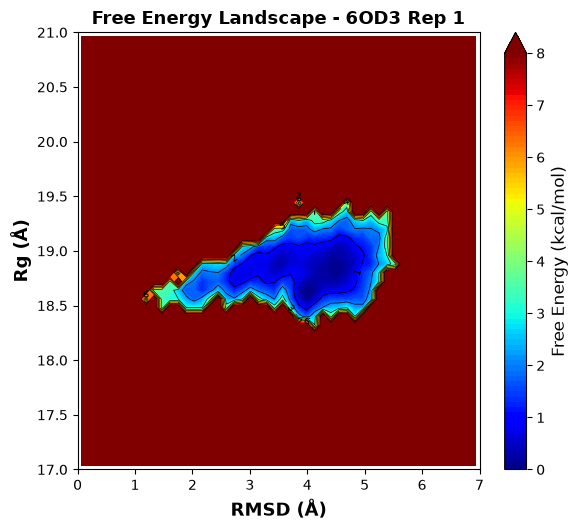

Rep 1: global minimum at RMSD = 3.99 Å, Rg = 18.64 Å


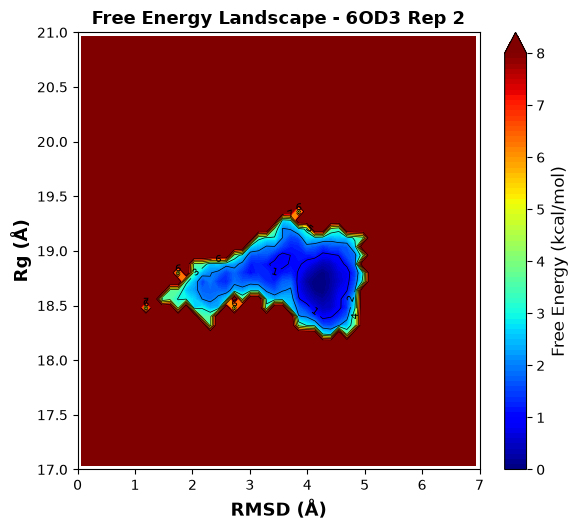

Rep 2: global minimum at RMSD = 4.27 Å, Rg = 18.64 Å


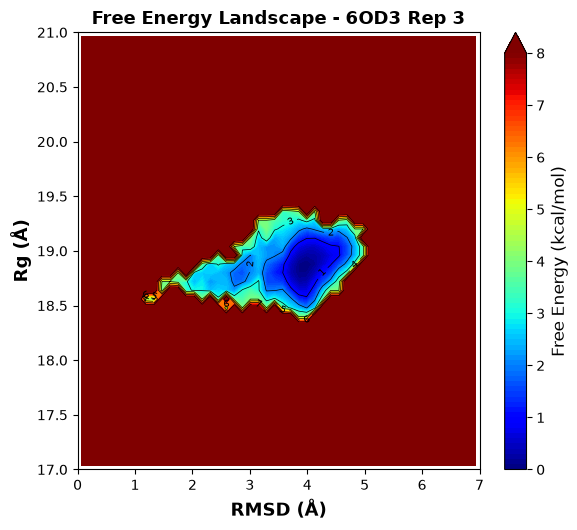

Rep 3: global minimum at RMSD = 3.99 Å, Rg = 18.88 Å


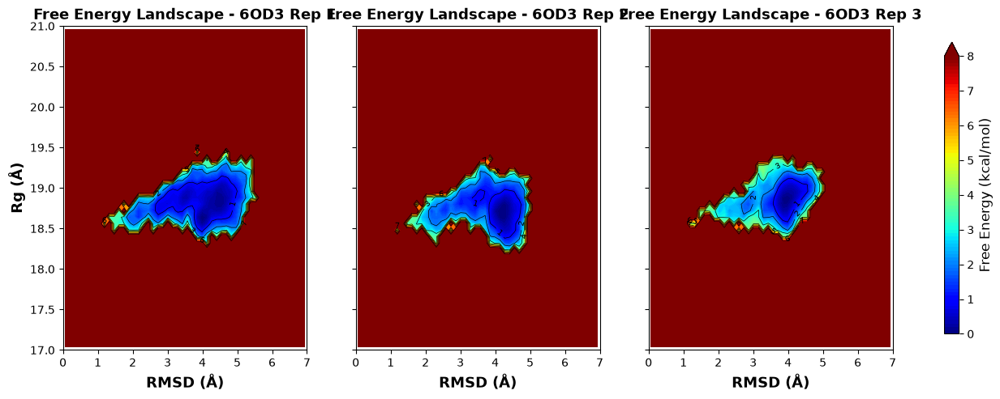

In [9]:
# ==============================================================================
# 7. FREE ENERGY LANDSCAPE (RMSD vs Rg) -- all 3 replicates
#    Uses PSF, REF_PDB, pat (step5_N.dcd pattern), STRIDE, COMPLEX, atoms_sel()
#    and keep_together() from the setup cell, so run that cell first.
# ==============================================================================
from MDAnalysis.analysis.rms import rmsd as rmsd_fn

# ---- settings ----------------------------------------------------------------
# Folder for each replicate (each must hold step3_input.psf/.pdb and step5_N.dcd).
# "." = the folder this notebook is running in.
REPLICATE_DIRS = {
    "Rep 1": "../../1/namd",
    "Rep 2": ".",
    "Rep 3": "../../3/namd",
}
SYSTEM_NAME = "6OD3"
FEL_SEL     = atoms_sel(COMPLEX, "name CA P")   # same atoms as the "Full Complex" RMSD
                                                # (use PROTEIN instead of COMPLEX for protein only)
TEMP_K      = 310.15        # K -- CHARMM-GUI default; change if you ran at 310 K
N_BINS      = 50            # histogram bins per axis
FE_MAX      = 8.0           # kcal/mol, top of the colorbar
RECOMPUTE   = False         # True = ignore saved fel_rmsd_rg.csv files and recalculate
kB = 0.0019872041           # kcal/(mol·K)

# ---- RMSD + Rg for one replicate (one pass through the trajectory) ------------
def rmsd_rg_for(folder):
    cache = os.path.join(folder, "fel_rmsd_rg.csv")
    if os.path.exists(cache) and not RECOMPUTE:
        df = pd.read_csv(cache)
        print(f"  loaded saved values from {cache}")
        return df["rmsd_A"].values, df["rg_A"].values

    segs = sorted((int(m.group(1)), f) for f in os.listdir(folder) if (m := pat.match(f)))
    segs = [os.path.join(folder, f) for _, f in segs]
    if not segs:
        raise FileNotFoundError(f"No step5_N.dcd files in {os.path.abspath(folder)}")
    uu = mda.Universe(os.path.join(folder, PSF), segs)
    rr = mda.Universe(os.path.join(folder, PSF), os.path.join(folder, REF_PDB))

    # same PBC handling as the setup cell
    cplx = uu.select_atoms(COMPLEX)
    chains = list(dict.fromkeys(cplx.segids))
    uu.trajectory.add_transformations(
        unwrap(cplx), keep_together([cplx.select_atoms(f"segid {s}") for s in chains]))

    sel = uu.select_atoms(FEL_SEL)
    ref_pos = rr.select_atoms(FEL_SEL).positions.copy()
    assert sel.n_atoms == len(ref_pos), "Trajectory and reference selections don't match"

    out = np.array([(rmsd_fn(sel.positions, ref_pos, center=True, superposition=True),
                     sel.radius_of_gyration())
                    for ts in uu.trajectory[::STRIDE]])
    pd.DataFrame({"rmsd_A": out[:, 0], "rg_A": out[:, 1]}).to_csv(cache, index=False)
    print(f"  {len(out)} frames, {len(segs)} segments -> saved {cache}")
    return out[:, 0], out[:, 1]

fel_data = {}
for name, folder in REPLICATE_DIRS.items():
    print(f"{name}: {os.path.abspath(folder)}")
    fel_data[name] = rmsd_rg_for(folder)

# ---- shared bins so all replicates are on the same axes -------------------------
all_rmsd = np.concatenate([d[0] for d in fel_data.values()])
all_rg   = np.concatenate([d[1] for d in fel_data.values()])
x_lim = (0, np.ceil(all_rmsd.max() + 0.5))
y_lim = (np.floor(all_rg.min() - 1), np.ceil(all_rg.max() + 1))
xedges = np.linspace(*x_lim, N_BINS + 1)
yedges = np.linspace(*y_lim, N_BINS + 1)
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])

def free_energy(x, y):
    """G = -kT ln P, with the deepest minimum set to 0. Unvisited bins -> above FE_MAX."""
    H, _, _ = np.histogram2d(x, y, bins=[xedges, yedges])
    P = H / H.sum()
    with np.errstate(divide="ignore"):
        G = -kB * TEMP_K * np.log(P)
    G -= G[np.isfinite(G)].min()
    G[~np.isfinite(G)] = FE_MAX + 1
    return G.T                      # rows = Rg, columns = RMSD

fill_levels = np.linspace(0, FE_MAX, 81)
line_levels = np.arange(1, FE_MAX)  # labelled contour lines at 1-7 kcal/mol

def plot_fel(ax, G, title):
    cf = ax.contourf(xc, yc, G, levels=fill_levels, cmap="jet", extend="max")
    cs = ax.contour(xc, yc, G, levels=line_levels, colors="black", linewidths=0.5)
    ax.clabel(cs, inline=True, fontsize=7, fmt="%d")
    ax.set_xlim(x_lim)
    ax.set_ylim(y_lim)
    ax.set_xlabel("RMSD (Å)", fontsize=13, fontweight="bold")
    ax.set_ylabel("Rg (Å)", fontsize=13, fontweight="bold")
    ax.set_title(f"Free Energy Landscape - {title}", fontsize=13, fontweight="bold")
    return cf

fel_G = {name: free_energy(*xy) for name, xy in fel_data.items()}

# ---- one figure per replicate ---------------------------------------------------
for name, G in fel_G.items():
    fig, ax = plt.subplots(figsize=(6, 5.4))
    cf = plot_fel(ax, G, f"{SYSTEM_NAME} {name}")
    cbar = fig.colorbar(cf, ax=ax, ticks=range(int(FE_MAX) + 1))
    cbar.set_label("Free Energy (kcal/mol)", fontsize=12)
    fig.tight_layout()
    fig.savefig(f"FEL_{SYSTEM_NAME}_{name.replace(' ', '_')}.png", dpi=300)
    plt.show()

    # where the global minimum is
    iy, ix = np.unravel_index(np.argmin(G), G.shape)
    print(f"{name}: global minimum at RMSD = {xc[ix]:.2f} Å, Rg = {yc[iy]:.2f} Å")

# ---- all replicates side by side, one shared colorbar ----------------------------
fig, axes = plt.subplots(1, len(fel_G), figsize=(5.5 * len(fel_G), 5.2), sharey=True)
for ax, (name, G) in zip(np.atleast_1d(axes), fel_G.items()):
    cf = plot_fel(ax, G, f"{SYSTEM_NAME} {name}")
for ax in np.atleast_1d(axes)[1:]:
    ax.set_ylabel("")
cbar = fig.colorbar(cf, ax=axes, ticks=range(int(FE_MAX) + 1), shrink=0.9)
cbar.set_label("Free Energy (kcal/mol)", fontsize=12)
fig.savefig(f"FEL_{SYSTEM_NAME}_all_replicates.png", dpi=300, bbox_inches="tight")
plt.show()

Rep 1: 10000 frames, segments ['PROA', 'PROB'] -> saved /deac/phy/classes/phy320-fa-2026/millg25/Project-1-PHY320620-Fall2026/6od3-1-R576T/1/namd/dssp_timeseries.npz


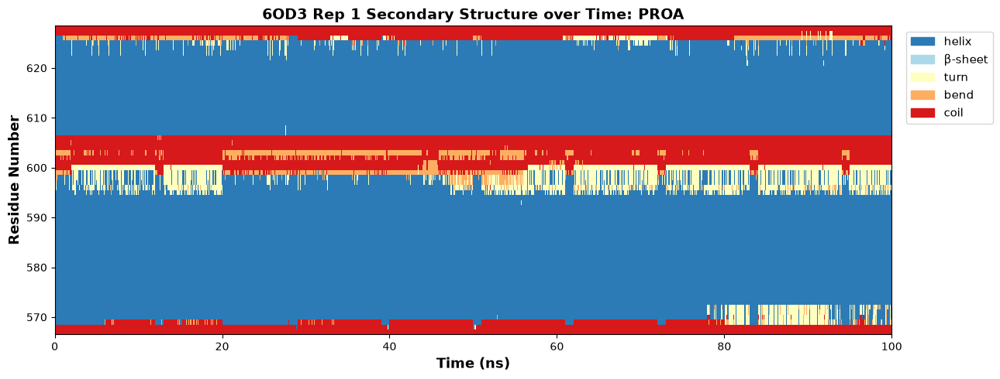

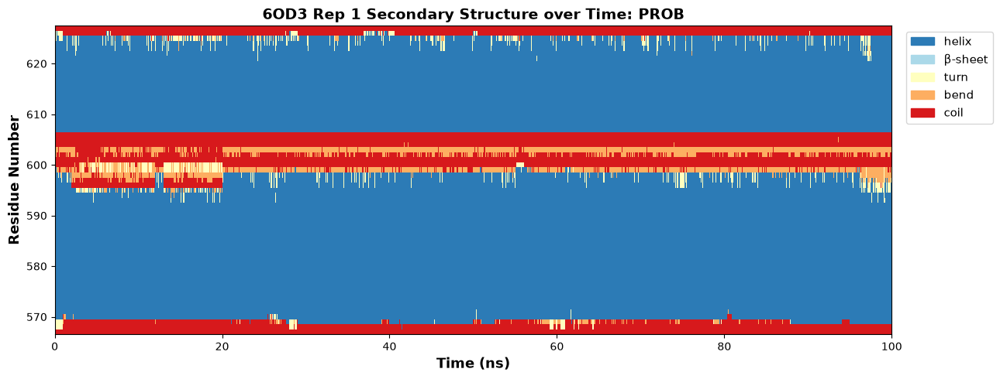

Rep 2: 10000 frames, segments ['PROA', 'PROB'] -> saved /deac/phy/classes/phy320-fa-2026/millg25/Project-1-PHY320620-Fall2026/6od3-1-R576T/2/namd/dssp_timeseries.npz


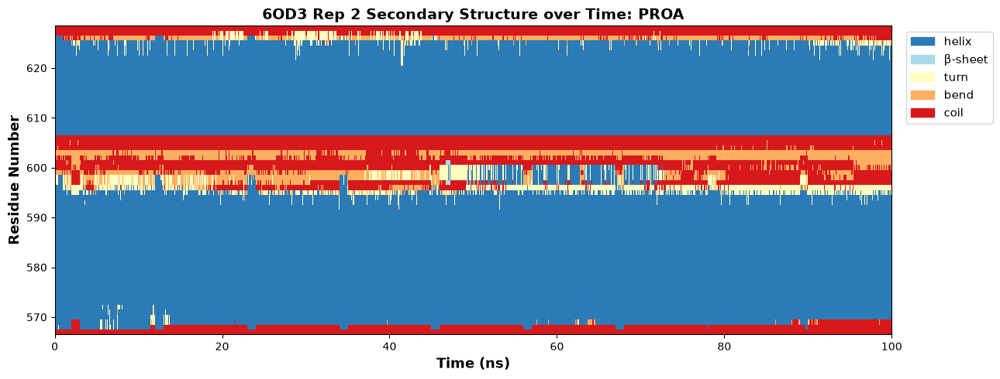

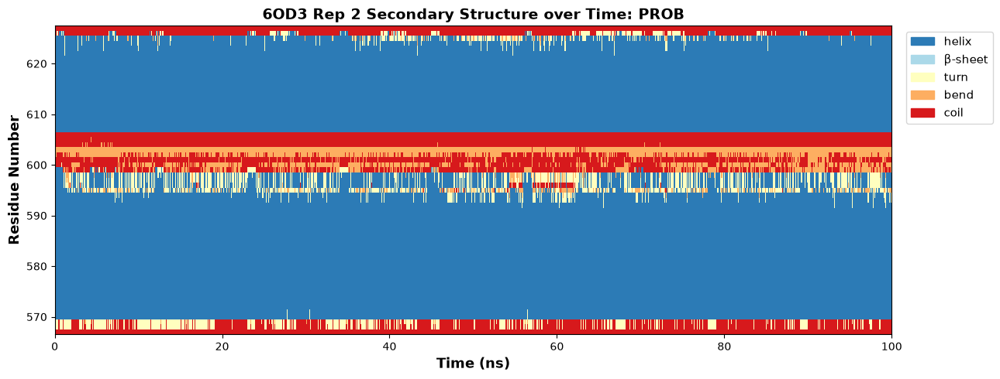

Rep 3: 10000 frames, segments ['PROA', 'PROB'] -> saved /deac/phy/classes/phy320-fa-2026/millg25/Project-1-PHY320620-Fall2026/6od3-1-R576T/3/namd/dssp_timeseries.npz


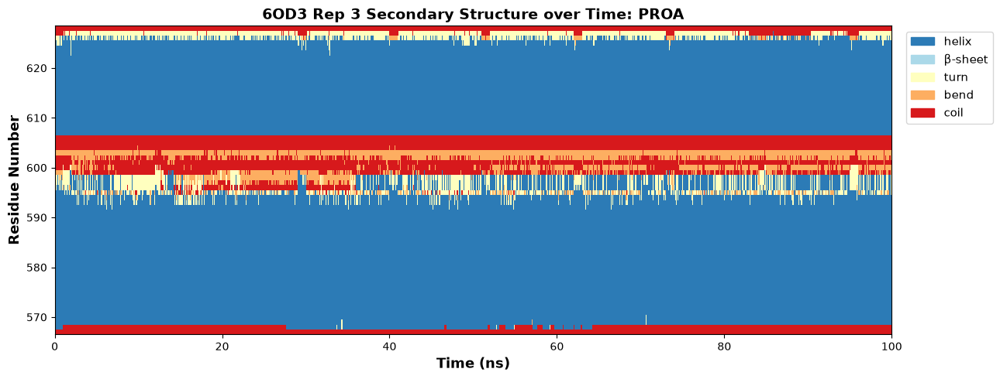

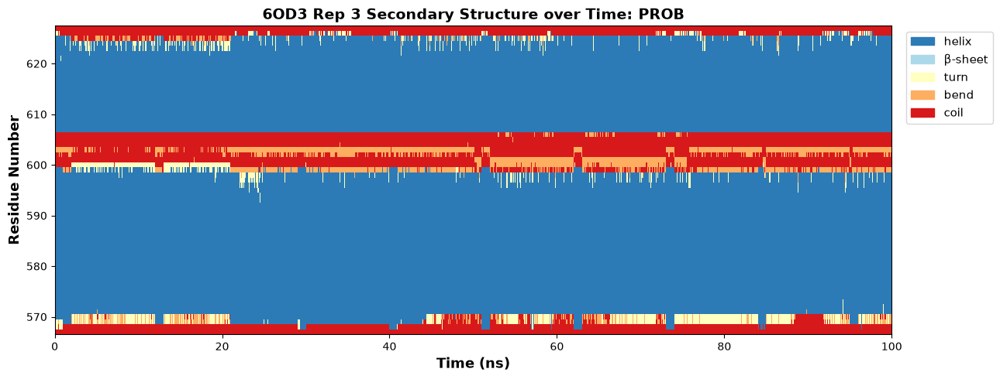

Rep 1 PROA: helix 74.3%, β-sheet 0.0%, turn 5.3%, bend 2.7%, coil 17.7%
Rep 1 PROB: helix 77.0%, β-sheet 0.0%, turn 1.7%, bend 4.0%, coil 17.3%
Rep 2 PROA: helix 73.9%, β-sheet 0.0%, turn 3.6%, bend 5.6%, coil 16.8%
Rep 2 PROB: helix 74.8%, β-sheet 0.0%, turn 4.8%, bend 5.0%, coil 15.3%
Rep 3 PROA: helix 75.8%, β-sheet 0.0%, turn 5.3%, bend 4.8%, coil 14.1%
Rep 3 PROB: helix 77.2%, β-sheet 0.0%, turn 2.7%, bend 3.9%, coil 16.2%


In [11]:
# ==============================================================================
# SECONDARY STRUCTURE (DSSP) OVER TIME -- one map per replicate per protein chain
#   Uses FOLDERS, TOP_NAME and TRAJ_FILES from earlier cells.
# ==============================================================================
# If mdtraj isn't installed: !pip install --user mdtraj   (then restart the kernel)
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import mdtraj as md

# ---- settings ----------------------------------------------------------------
SYSTEM_NAME   = "6OD3"
SS_SEGIDS     = None      # e.g. ["PROA", "PROB"]; None = every protein segment found
CHAIN_NAMES   = {}        # optional nicer titles, e.g. {"PROA": "Chain A", "PROB": "Chain B"}
NS_PER_FRAME  = 0.01      # same as the RMSD/Rg cell
MAX_NS        = 100       # None = whole trajectory
SS_STRIDE     = 1         # every Nth frame (10 = 10x faster, still plenty for this plot)
CHUNK         = 500       # frames read at a time (keeps memory low)
RECOMPUTE_SS  = False     # True = ignore saved dssp_timeseries.npz files

import os
BASE = "/deac/phy/classes/phy320-fa-2026/millg25/Project-1-PHY320620-Fall2026/6od3-1-R576T"
FOLDERS = {
    "Rep 1": f"{BASE}/1/namd",
    "Rep 2": f"{BASE}/2/namd",
    "Rep 3": f"{BASE}/3/namd",
}
TOP_NAME = "step3_input.psf"
TRAJ_FILES = {label: os.path.join(d, f"6od3rep{label.split()[-1]}_step5.dcd")
              for label, d in FOLDERS.items()}

# DSSP code -> category  (H/G/I helix, E/B sheet, T turn, S bend, blank coil)
SS_CLASSES = ["helix", "β-sheet", "turn", "bend", "coil"]
SS_COLORS  = ["#2c7bb6", "#abd9e9", "#ffffbf", "#fdae61", "#d7191c"]
CODE_TO_CLASS = {"H": 0, "G": 0, "I": 0, "E": 1, "B": 1, "T": 2, "S": 3, " ": 4, "C": 4, "NA": 4}

def protein_segments(top):
    segs = {}
    for res in top.residues:
        if res.is_protein:
            segs.setdefault(res.segment_id or f"chain{res.chain.index}", []).append(res)
    return segs

def dssp_for(label, folder, traj_file):
    cache = os.path.join(folder, "dssp_timeseries.npz")
    if os.path.exists(cache) and not RECOMPUTE_SS:
        z = np.load(cache, allow_pickle=True)
        print(f"{label}: loaded {cache}")
        return z["out"].item()

    top = md.load_psf(os.path.join(folder, TOP_NAME))
    segs = protein_segments(top)
    wanted = SS_SEGIDS or list(segs)
    prot_atoms = np.array([a.index for s in wanted for r in segs[s] for a in r.atoms])
    sub_top = top.subset(prot_atoms)
    stop = int(round(MAX_NS / NS_PER_FRAME)) if MAX_NS else None

    codes, frames_done = [], 0
    for chunk in md.iterload(traj_file, top=top, chunk=CHUNK, atom_indices=prot_atoms):
        if stop is not None and frames_done >= stop:
            break
        if stop is not None:
            chunk = chunk[: max(0, stop - frames_done)]
        idx = np.arange(frames_done, frames_done + chunk.n_frames)
        keep = (idx % SS_STRIDE) == 0
        if keep.any():
            codes.append(md.compute_dssp(chunk[keep], simplified=False))
        frames_done += chunk.n_frames
    codes = np.vstack(codes)                                    # (frames, residues)
    frame_idx = np.arange(0, frames_done, SS_STRIDE)[: len(codes)]

    to_class = np.vectorize(lambda c: CODE_TO_CLASS.get(c, 4))
    classes = to_class(codes).astype(np.int8)

    out, col = {}, 0
    sub_res = list(sub_top.residues)
    for s in wanted:
        n = len(segs[s])
        resids = np.array([r.resSeq for r in sub_res[col:col + n]])
        out[s] = {"time_ns": (frame_idx + 1) * NS_PER_FRAME, "resid": resids,
                  "ss": classes[:, col:col + n]}
        col += n
    np.savez_compressed(cache, out=np.array(out, dtype=object))
    print(f"{label}: {len(frame_idx)} frames, segments {wanted} -> saved {cache}")
    return out

def plot_ss_map(ss, title, fname):
    t, resid, grid = ss["time_ns"], ss["resid"], ss["ss"]
    cmap = ListedColormap(SS_COLORS)
    norm = BoundaryNorm(np.arange(-0.5, len(SS_CLASSES)), cmap.N)
    dt = t[1] - t[0] if len(t) > 1 else NS_PER_FRAME
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.imshow(grid.T, aspect="auto", origin="lower", cmap=cmap, norm=norm,
              interpolation="nearest",
              extent=[t[0] - dt, t[-1], resid[0] - 0.5, resid[-1] + 0.5])
    ax.set_xlabel("Time (ns)", fontsize=13, fontweight="bold")
    ax.set_ylabel("Residue Number", fontsize=13, fontweight="bold")
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlim(0, t[-1])
    ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(SS_COLORS, SS_CLASSES)],
              loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=11)
    fig.tight_layout()
    fig.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

ss_data = {}
for label, d in FOLDERS.items():
    ss_data[label] = dssp_for(label, d, TRAJ_FILES[label])
    for seg, ss in ss_data[label].items():
        chain = CHAIN_NAMES.get(seg, seg)
        rep = label.replace(" ", "")
        plot_ss_map(ss, f"{SYSTEM_NAME} {label} Secondary Structure over Time: {chain}",
                    f"{SYSTEM_NAME}_{rep}_dssp_{seg}.png")

# ---- % of time in each structure, per replicate (handy for the caption) ----------
for label, segs in ss_data.items():
    for seg, ss in segs.items():
        frac = [(ss["ss"] == k).mean() * 100 for k in range(len(SS_CLASSES))]
        print(f"{label} {CHAIN_NAMES.get(seg, seg)}: " +
              ", ".join(f"{c} {f:.1f}%" for c, f in zip(SS_CLASSES, frac)))

In [ ]:
# Save this notebook first (File -> Save), then export it to HTML
!jupyter nbconvert --to html 6od3_analysis.ipynb

In [2]:
!git add Advanced_Analysis.ipynb
!git commit -m "Add Part 3 advanced MD simulation analysis"
!git push origin main

[main c77d410] Add Part 3 advanced MD simulation analysis
 Committer: Grace Miller <millg25@cpu-intel-69.deac.wfu.edu>
Your name and email address were configured automatically based
on your username and hostname. Please check that they are accurate.
You can suppress this message by setting them explicitly. Run the
following command and follow the instructions in your editor to edit
your configuration file:

    git config --global --edit

After doing this, you may fix the identity used for this commit with:

    git commit --amend --reset-author

 1 file changed, 1775 insertions(+)
 create mode 100644 6od3-1-R576T/2/namd/Advanced_Analysis.ipynb

(gnome-ssh-askpass:3721066): Gtk-WARNING **: 19:42:25.663: cannot open display: 
error: unable to read askpass response from '/usr/libexec/openssh/gnome-ssh-askpass'
Username for 'https://github.com': ^C
